# Discovery of sea turtles from body parts

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sadda/turtle_re_id/blob/master/examples/discovery.ipynb)

This notebook shows how to use the `animal_re_id` package to find the same sea turtles in a set of photos when no **database** of known turtles exists. All photos form the **query**, and every encounter is compared with all other encounters. The goal is to group the encounters which show the same turtle. As in the [introduction notebook](introduction.ipynb), the turtles are first segmented into body parts (head, front flippers, hind flippers), and each body part is matched separately.

The workflow consists of:

1. **Detection** – the TurtleDetector finds the body parts in every photo.
2. **Re-identification** – every body part of every encounter is compared with the same body part in all other encounters.
3. **Verification** – the most promising pairs of encounters are exported for manual verification in a visual app.
4. **Grouping** – the verified answers are used to group the encounters into individual turtles.

All computed results are stored and reused in the same way as in the introduction notebook.

## 0. Configuration and Data Preparation

When running in Google Colab, we first install the `animal_re_id` package. Then we load all required functions.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "animal-re-id[models] @ git+https://github.com/sadda/turtle_re_id"

In [2]:
import os
import urllib.request
import warnings
import zipfile

from wildlife_datasets.datasets import Dataset_FolderStructured
from wildlife_tools.similarity import MaskedPairSelector, MetadataIgnoreMask, TopkPairSelector

from animal_re_id.datasets import TurtlesFromMetadata
from animal_re_id.datasets.utils import check_image_ids
from animal_re_id.models import EncounterPredictions, Wildfusion_Similarity, get_pipeline_aliked, get_pipeline_miew, merge_data, run_detection_cached, turtle_detector
from animal_re_id.verification import answers_to_groups, generate_answers_discovery

warnings.filterwarnings("ignore", message=".*copying from a non-meta parameter.*")

The notebook expects all photos in the folder `root`. We specify that we run the computation on CPU, not GPU. The option `img_load="bbox"` means that every body part is cropped by its bounding box before matching, and `matching_parts` lists the body parts that are used for re-identification.

In [3]:
root = "data_discovery"
root_cache = "output/cache_Example_discovery"

device = "cpu"
img_load = "bbox"
matching_parts = ["heads", "front flippers", "hind flippers"]

We now download a small subset of [SeaTurtleID2022](https://www.kaggle.com/datasets/wildlifedatasets/seaturtleid2022) with 10 encounters and 1-2 photos each, stored as `<date>/<encounter>/<photo>`. The encounters show 6 turtles: four of them (`t023`, `t217`, `t243` and `t441`) were seen in two encounters, and two of them (`t048` and `t323`) only once. There are therefore 4 pairs of encounters which should be found. The true identities are given at the end of the notebook so that the results can be checked.

In [4]:
url = "https://raw.githubusercontent.com/sadda/wildlife-labels/refs/heads/main/Example/data_discovery.zip"
file_name = "data_discovery.zip"

if not os.path.exists(root):
    urllib.request.urlretrieve(url, file_name)
    with zipfile.ZipFile(file_name) as f:
        f.extractall(root)
    os.remove(file_name)

    os.remove(f"{root}/metadata.csv")
    os.remove(f"{root}/segmentation.csv")

## 1. Detection

The metadata are created from the folder structure by `Dataset_FolderStructured`. The identity is unknown, and the photos of the same turtle taken on the same day form one **encounter** (`<date>/<folder>`). Predictions are made for whole encounters, so the evidence from all photos of an encounter is combined.

The [TurtleDetector](https://huggingface.co/BVRA/TurtleDetector) then detects the turtle body, the head and the four flippers in every photo and stores their bounding boxes, masks, labels and confidence scores. Both tables are saved next to the photos as `metadata.csv` and `segmentation.csv`. Finally, example photos are plotted.

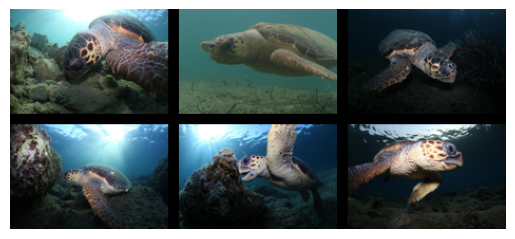

In [5]:
model = turtle_detector()
dataset = Dataset_FolderStructured(root, levels=("date", "encounter"))
dataset.metadata["encounter_id"] = dataset.metadata["date"] + "/" + dataset.metadata["encounter"]
dataset.metadata.to_csv(f"{root}/metadata.csv", index=False)

run_detection_cached(dataset, model, f"{root}/segmentation.csv")

dataset.plot_grid(idx=range(6), n_rows=2, n_cols=3, rotate=False);

The dataset in `TurtlesFromMetadata` loads `metadata.csv` together with `segmentation.csv`. Every detected body part becomes one row, and detections with low confidence are removed. Since the identities are unknown, every encounter is treated as its own identity. The candidates for every encounter are then the other encounters. The table shows how many body parts of each type were kept.

In [6]:
dataset_kwargs = {"img_load": img_load}
query_dataset = TurtlesFromMetadata(root, dataset_kwargs=dataset_kwargs)
query_metadata = query_dataset.wildlife_dataset.metadata
query_metadata["identity"] = query_metadata["encounter_id"]
query_metadata["label"].value_counts()


label
head          17
turtle        17
flipper_fl    16
flipper_fr    14
flipper_hr     8
flipper_hl     3
Name: count, dtype: int64

The detector labels are grouped into **matching parts**: `heads`, `front flippers` (left and right) and `hind flippers` (left and right). Each grid shows the crops of one matching part.

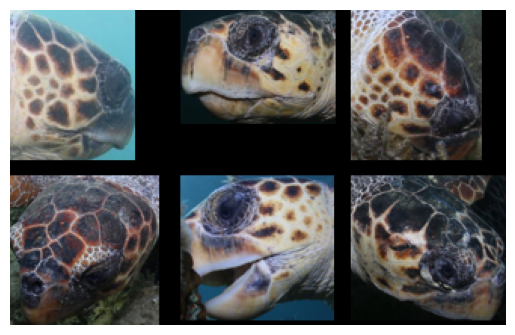

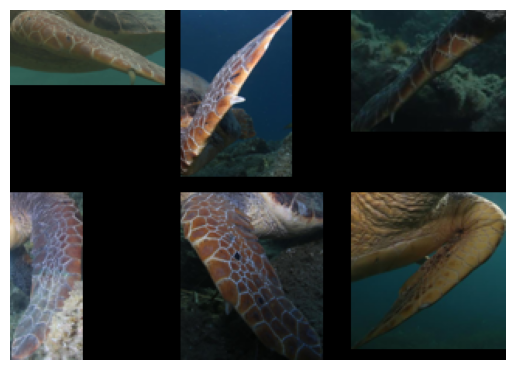

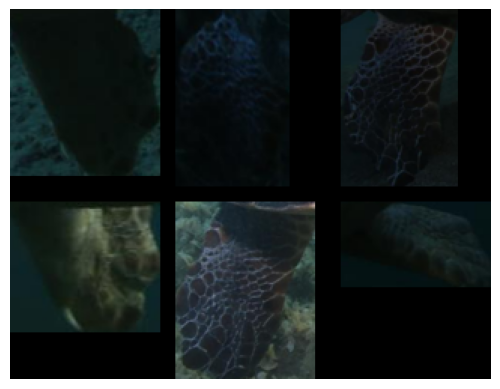

In [7]:
for matching_part in matching_parts:
    wildlife_dataset = query_dataset.for_matching_part(matching_part).wildlife_dataset
    wildlife_dataset.plot_grid(n_rows=2, n_cols=3, rotate=False)

## 2. Re-identification based on individual parts

The matching is the same as in the introduction notebook, with two differences:

- The query is compared with itself instead of with a database.
- `MaskedPairSelector` ignores the pairs of photos from the same encounter. Otherwise, every encounter would be the best candidate for itself.

`EncounterPredictions.classify` and `merge_data` then create and merge the predictions of all matching parts, where the candidate identities are the other encounters.

In [8]:
cache_prefix = f"{root_cache}/{img_load}"
miew = get_pipeline_miew(device=device, cache_prefix=cache_prefix)
aliked = get_pipeline_aliked(device=device, cache_prefix=cache_prefix)
B = 5

pair_selector = MaskedPairSelector(TopkPairSelector(), MetadataIgnoreMask(cols_equal=["encounter_id"]))
wildfusion = Wildfusion_Similarity(miew, aliked, B=B, pair_selector=pair_selector)

predictions = []
for matching_part in matching_parts:
    query = query_dataset.for_matching_part(matching_part).wildlife_dataset
    check_image_ids(query.metadata)

    similarity = wildfusion(query, query)
    prediction = EncounterPredictions.classify(similarity, query, query, matching_part, "miew-aliked", k_max=10)
    predictions.append(prediction)

merged = merge_data(predictions)

## 3. Verification

We convert the merged predictions into candidate pairs for verification. Every row is one pair of encounters, including the two images that produced the match, the matching part and the raw number of matched keypoints (`similarity_orig`). Every pair of encounters appears twice in the predictions (A as a candidate for B and B as a candidate for A), and `max_per_identity=1` keeps only one of them. `max_per_encounter` limits the number of candidates per encounter, and `max_matches` limits the total number of pairs.

The pairs are saved to `verification_data.csv`, which is the input format of the [Image Comparator app](https://github.com/sadda/image-comparator). There, an annotator decides for every pair whether the two turtles are the same, and the answers are saved to `answers.csv`. Manual verification is optional for this notebook.

In [9]:
file_name_verification = "output/verification_data.csv"

verification = merged.extract_highest_predictions(max_matches=24, max_per_encounter=4, max_per_identity=1, sort_by="similarity_orig")
verification = verification.sort_values("similarity_orig", ascending=False, ignore_index=True)
verification.to_csv(file_name_verification, index=False)
verification[["encounter1", "encounter2", "matching_part", "similarity_orig"]]

,encounter1,encounter2,matching_part,similarity_orig
0,2019-09-01/1,2019-09-02/1,front flippers,94.0
1,2019-09-04/1,2021-06-27/1,heads,49.0
2,2019-09-01/2,2021-06-22/1,heads,40.0
3,2018-06-22/1,2021-06-22/1,heads,33.0
4,2019-09-02/1,2021-06-27/1,heads,21.0
5,2019-09-01/3,2019-09-02/1,front flippers,18.0
6,2019-09-02/1,2019-09-04/1,heads,18.0
7,2016-09-11/1,2019-09-04/1,heads,17.0
8,2018-06-22/1,2021-06-27/1,heads,17.0
9,2019-09-01/2,2019-09-02/1,front flippers,17.0


## 4. Grouping

If the verification has been performed manually, copy the file `answers.csv` to the `output` folder and load it via

```python
answers = pd.read_csv("output/answers.csv")
```

To run this example without the app, `generate_answers_discovery` simulates an annotator who knows the true identities and selects either `same` or `different`. Three of the four pairs which should be found have the highest scores (94, 49 and 40) and are easily answered as `same`. The last pair (`2018-06-22/1` and `2018-08-22/1`, both `t217`) has the very low score of 10. This score is an accident, not a match. The simulated annotator answers it `same` only because it knows the true identities.

In [10]:
true_identities = {
    "2016-09-11/1": "t048",
    "2018-06-22/1": "t217",
    "2018-08-22/1": "t217",
    "2019-09-01/1": "t023",
    "2019-09-01/2": "t243",
    "2019-09-01/3": "t323",
    "2019-09-02/1": "t023",
    "2019-09-04/1": "t441",
    "2021-06-22/1": "t243",
    "2021-06-27/1": "t441",
}

answers = generate_answers_discovery(verification, true_identities)
answers[["encounter1", "encounter2", "matching_part", "similarity_orig", "answer"]]

,encounter1,encounter2,matching_part,similarity_orig,answer
0,2019-09-01/1,2019-09-02/1,front flippers,94.0,same
1,2019-09-04/1,2021-06-27/1,heads,49.0,same
2,2019-09-01/2,2021-06-22/1,heads,40.0,same
3,2018-06-22/1,2021-06-22/1,heads,33.0,different
4,2019-09-02/1,2021-06-27/1,heads,21.0,different
5,2019-09-01/3,2019-09-02/1,front flippers,18.0,different
6,2019-09-02/1,2019-09-04/1,heads,18.0,
7,2016-09-11/1,2019-09-04/1,heads,17.0,different
8,2018-06-22/1,2021-06-27/1,heads,17.0,different
9,2019-09-01/2,2019-09-02/1,front flippers,17.0,different


`answers_to_groups` converts the answers into groups of encounters. Encounters answered `same`, directly or through other encounters, form one group, which is one turtle. For checking, the true identities are added to every group.

In [11]:
groups = answers_to_groups(answers)
groups["true_identities"] = groups["encounters"].map(lambda encounters: [true_identities[encounter] for encounter in encounters])
groups

,encounters,true_identities
0,[2016-09-11/1],[t048]
1,"[2018-06-22/1, 2018-08-22/1]","[t217, t217]"
2,"[2019-09-01/1, 2019-09-02/1]","[t023, t023]"
3,"[2019-09-01/2, 2021-06-22/1]","[t243, t243]"
4,[2019-09-01/3],[t323]
5,"[2019-09-04/1, 2021-06-27/1]","[t441, t441]"


The photos of the two encounters of `t217` show why this pair cannot be found. The photos were taken from opposite sides of the turtle, and since the scale patterns differ between the left and right side, there is nothing to match. A real annotator would not be able to confirm this pair either. In this case, the turtle is found again only when it is photographed from the same side in another encounter.

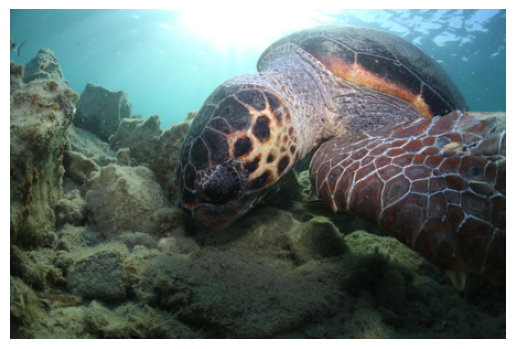

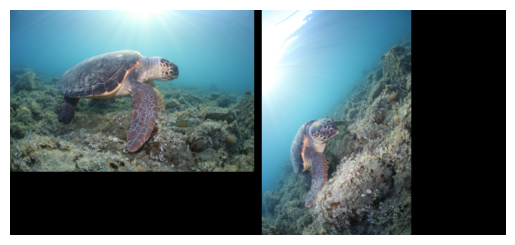

In [12]:
for encounter_id in ["2018-08-22/1", "2018-06-22/1"]:
    mask = dataset.metadata["encounter_id"] == encounter_id
    dataset.plot_grid(idx=mask, n_rows=1, n_cols=mask.sum(), rotate=False, img_min=300)